# Lecture 8: calibration on Irish data

**ECU44291 Quantitative Macroeconomics, Week 9.**

At the end of the last lecture we found $\beta$ by solving the model inside a root finder. Today is about the numbers that go in: where each one comes from, whether the model and the data measure the same thing, and how much the answers move when a choice changes. The data are the files you will use for M3 (the same as `data/` in your project). The sixty-cohort economy is on the slides; building it is the task for milestone 3.

This is the complete notebook, and I walk through most of it in lecture. 

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# The data should sit next to this notebook in code/data/; on Colab they are read from GitHub.
DATA = "code/data/" if Path("code/data").exists() else \
    "https://raw.githubusercontent.com/joekopecky/ECU44291-lectures/main/week08/code/data/"

## Task 1: the numbers

Each file has a README entry (`code/data/README.md`): what it measures, the source and table code, and the caveats. Read it before you use a series.

**Intuition before running:** in 2025, what fraction of Irish GDP is GNI\*? More or less than three quarters?

In [2]:
gdp = pd.read_csv(DATA + "gdp_gni_star.csv")
cso = pd.read_csv(DATA + "capital_output_cso.csv")
pwt = pd.read_csv(DATA + "capital_output_pwt.csv")
share = pd.read_csv(DATA + "capital_share_pwt.csv")
dep = pd.read_csv(DATA + "depreciation_pwt.csv")
pension = pd.read_csv(DATA + "pension_parameters.csv")

print("GNI*/GDP, 2025:            ", gdp.gni_star_over_gdp.iloc[-1])
print("K/Y, CSO stock over GDP:   ", cso.k_over_gdp.iloc[-1], f"({cso.year.iloc[-1]})")
print("K/Y, CSO stock over GNI*:  ", cso.k_over_gni_star.iloc[-1], f"({cso.year.iloc[-1]})")
print("K/Y, Penn World Table:     ", pwt.k_over_y.iloc[-1], f"({pwt.year.iloc[-1]})")
print("alpha, 2023:               ", share.alpha.iloc[-1])
print("alpha, mean 2000-2014:     ", round(share[share.year <= 2014].alpha.mean(), 3))
print("delta, 2023:               ", dep.delta.iloc[-1])
print("delta, mean 2000-2014:     ", round(dep[dep.year <= 2014].delta.mean(), 3))
print(pension[pension.parameter == "replacement_rate"][["value", "period"]].to_string(index=False))

GNI*/GDP, 2025:             0.554
K/Y, CSO stock over GDP:    2.346 (2025)
K/Y, CSO stock over GNI*:   4.231 (2025)
K/Y, Penn World Table:      3.42 (2023)
alpha, 2023:                0.691
alpha, mean 2000-2014:      0.517
delta, 2023:                0.0747
delta, mean 2000-2014:      0.041
 value               period
 0.286                 2025
 0.283 2026 (2026Q1-2026Q2)


Three measures of one ratio, and an $\alpha$ that depends on the years you average over. None of them is wrong: they measure different things. The slides go through what each one counts.

## Task 2: who is alive

The sixty-cohort model has households aged 21 to 80, working to 65 and retired from 66. The cohort sizes $\mu_j$ come from the population by age. The CSO's old-age dependency ratio is the population aged 65 and over divided by the population aged 15 to 64.

**Intuition before running:** Would we expect the model's ratio of retirees to workers (66 to 80 over 21 to 65) to be above or below the CSO's ratio?

In [3]:
pop = pd.read_csv(DATA + "population_by_age.csv")
persons = pop.set_index("age").persons

model_ages = persons.loc[21:80]
mu = model_ages / model_ages.sum()              # cohort shares, summing to one
print(f"model:  66-80 over 21-65 = {persons.loc[66:80].sum() / persons.loc[21:65].sum():.3f}")
print(f"CSO:    65+   over 15-64 = {persons.loc[65:].sum() / persons.loc[15:64].sum():.3f}")

model:  66-80 over 21-65 = 0.197
CSO:    65+   over 15-64 = 0.245


Lower: the model leaves out everyone over 80 and counts 65-year-olds as workers. The two ratios are different objects, so compare the model with the model's own ratio, never with the CSO's.

## Task 3: the return your choices imply

The firm's first-order condition holds in every equilibrium of the model: $r + \delta = \alpha\, Y/K$. So once you have chosen $\alpha$, $\delta$ and a $K/Y$ target, you have also chosen the interest rate,
$$r = \frac{\alpha}{K/Y} - \delta,$$
before you solve anything. That makes it a check on whether your three choices fit together.

**Intuition before running:** with $\alpha = 0.69$ (2023) and $K/Y = 2.35$ (stock over GDP), is $r$ above or below 10% a year?

In [4]:
alphas = {"one third": 0.33,
          "2000-2014": share[share.year <= 2014].alpha.mean(),
          "2023": share.alpha.iloc[-1]}
ky = {"K/GDP": cso.k_over_gdp.iloc[-1], "PWT": pwt.k_over_y.iloc[-1], "K/GNI*": cso.k_over_gni_star.iloc[-1]}
delta = dep.delta.iloc[-1]                      # 2023

implied_r = pd.DataFrame({k: {a: alpha / v - delta for a, alpha in alphas.items()} for k, v in ky.items()})
print(implied_r.round(3))

           K/GDP    PWT  K/GNI*
one third  0.066  0.022   0.003
2000-2014  0.146  0.076   0.047
2023       0.220  0.127   0.089


A real return of a few percent a year is plausible; 22% is not, and neither is 0.3%. A combination that implies a strange $r$ will need a strange $\beta$ to hit it.

## The two-period OLG economy, as in Lectures 2 and 7

The same functions as last week: log utility, $\beta = 0.9$, $\alpha = 0.3$, $\delta = 0$, $\tau_L = 0.2$, $\tau_K = 0.15$, no pension. A period is a generation, about 30 years.

In [5]:
def params(**overrides):
    p = dict(alpha=0.3, A=1.0, beta=0.9, delta=0.0, tau_L=0.2, tau_K=0.15,
             t_y=0.0, t_o=0.0, tau_p=0.0, N_y=1.0, N_o=1.0)
    p.update(overrides)
    return p

def prices(K, p):
    L = p["N_y"]
    q = p["alpha"] * p["A"] * K ** (p["alpha"] - 1) * L ** (1 - p["alpha"])
    w = (1 - p["alpha"]) * p["A"] * K ** p["alpha"] * L ** (-p["alpha"])
    R = 1 + (1 - p["tau_K"]) * (q - p["delta"])
    return q, w, R

def pension_benefit(w, p):
    return p["tau_p"] * w * p["N_y"] / p["N_o"]

def savings(w, R, p):
    income_y = (1 - p["tau_L"] - p["tau_p"]) * w + p["t_y"]
    income_o = p["t_o"] + pension_benefit(w, p)
    return (p["beta"] * R * income_y - income_o) / ((1 + p["beta"]) * R)

def capital_supply(K, p):
    _, w, R = prices(K, p)
    return p["N_y"] * savings(w, R, p)

def solve_by_root(p):
    return brentq(lambda K: capital_supply(K, p) - K, 1e-3, 2.0, xtol=1e-12)

## Task 4: sensitivity

Move one parameter, hold the rest, solve the model again at each value, and plot what you care about. Here: $K/Y$ and $r$ against $\alpha$.

**Before you run:** as $\alpha$ rises, does $K/Y$ rise or fall? Why?

K/Y from 0.303 to 0.189;  r from 0.660 to 2.639


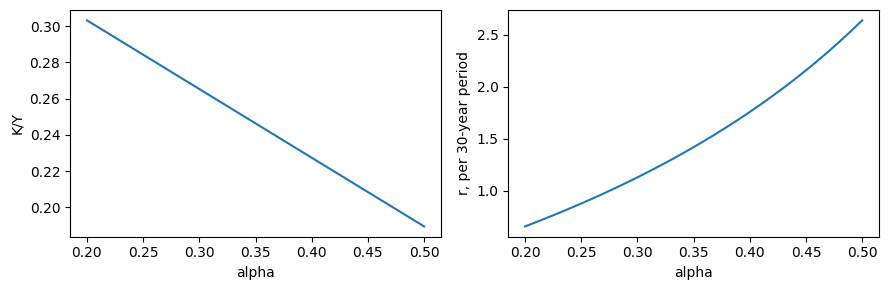

In [6]:
def sweep(name, values):
    """K/Y and r in the steady state, with one parameter set to each value in turn."""
    ky, r = [], []
    for v in values:
        p = params(**{name: v})
        K = solve_by_root(p)
        q, w, R = prices(K, p)
        ky.append(K / K ** p["alpha"])         # Y = K^alpha with L = 1
        r.append(q - p["delta"])
    return np.array(ky), np.array(r)

def plot_sweep(name, values):
    ky, r = sweep(name, values)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
    ax1.plot(values, ky); ax1.set_xlabel(name); ax1.set_ylabel("K/Y")
    ax2.plot(values, r);  ax2.set_xlabel(name); ax2.set_ylabel("r, per 30-year period")
    fig.tight_layout()
    print(f"K/Y from {ky[0]:.3f} to {ky[-1]:.3f};  r from {r[0]:.3f} to {r[-1]:.3f}")

plot_sweep("alpha", np.linspace(0.2, 0.5, 31))

**The mechanism.** The young save out of wages, and the wage bill is a share $1 - \alpha$ of output. A higher $\alpha$ leaves them less to save from, so capital per unit of output falls: here $K/Y = \beta(1-\tau_L)(1-\alpha)/(1+\beta)$. With less capital, and a larger share of output paid to it, the return $r = \alpha\, Y/K$ rises.

"$K/Y$ falls as $\alpha$ rises" is what the plot shows. The paragraph above is why. A sensitivity plot needs the second.

**Before you run the next cell:** we change one word, `"alpha"` to `"tau_K"`, the tax on capital income. What will the two lines look like?

K/Y from 0.265 to 0.265;  r from 1.131 to 1.131


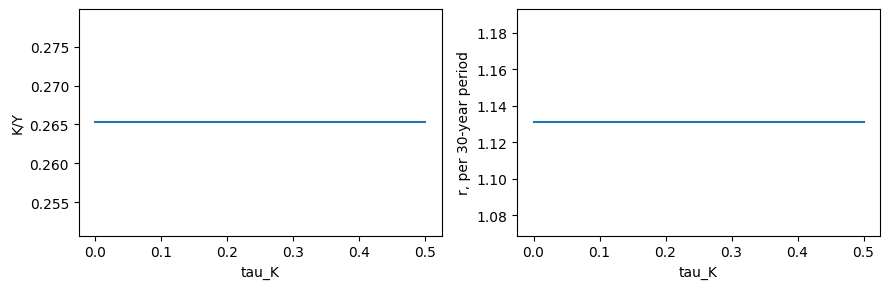

In [7]:
plot_sweep("tau_K", np.linspace(0.0, 0.5, 31))

Flat. With log utility and no pension, saving is a fixed share of the wage (Lecture 7's saving rule, first term), and $R$ does not enter it. A tax on the return changes what the old consume, not what the young save. In your sixty-cohort household the same tax may matter: whether it does is a question about your model, and the plot answers it.

## Task 5 (homework): calibrate the two-period economy to Ireland

A period here is 30 years, so output per period is about 30 years of annual output, and an annual $K/Y$ of 3 is a $K/Y$ of 0.1 per period. For each of the three Irish $K/Y$ measures in Task 3, find the $\beta$ per period that hits it (with `brentq`, as in Lecture 7, Task 5), and the annual discount factor $\beta^{1/30}$ it corresponds to. Check one of them against the closed form $K/Y = \beta(1-\tau_L)(1-\alpha)/(1+\beta)$.

In [ ]:
# Solution posted next week. Try it yourself first.


## Before the next lecture

- **M2, the proposal: Friday 13 November, 17:00.** Section 4, the calibration of each new parameter: its value or target, the source, and which parameter each target pins.
- **M3, the engine and its calibration: Tuesday 24 November, 17:00.** The data are in `data/` in your project, with the README.
- Task 5 above.
- Next lecture, Thursday 19 November: policy experiments and welfare by cohort.